# Naturaleza Lineal vs. No Lineal e Hiperparámetros Críticos
**Curso:** Aprendizaje de Máquina (IX ciclo, grupo B) — UNAP  
**Responsable:** Gutierrez Arratia Kevin Diego

## 1. Entrenamiento y tabla comparativa consolidada

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score

sys.path.insert(0, str(Path.cwd().parent / "src"))
from clustering_utils import set_minimalist_style, evaluate_clustering, plot_scatter_minimal

set_minimalist_style()

# 1. Datos estandarizados
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
y_iris = iris.target
X_iris_2d = PCA(n_components=2, random_state=42).fit_transform(X_iris)

X_moons_raw, y_moons = make_moons(n_samples=500, noise=0.08, random_state=42)
X_moons = StandardScaler().fit_transform(X_moons_raw)

X_circles_raw, y_circles = make_circles(n_samples=500, factor=0.5, noise=0.05, random_state=42)
X_circles = StandardScaler().fit_transform(X_circles_raw)

# 2. Modelos y predicciones
km_iris = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
y_km_iris = km_iris.fit_predict(X_iris)
y_db_iris = DBSCAN(eps=0.62, min_samples=5).fit_predict(X_iris)
y_sc_iris = SpectralClustering(n_clusters=3, affinity="nearest_neighbors", n_neighbors=10, random_state=42).fit_predict(X_iris)

km_moons = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)
y_km_moons = km_moons.fit_predict(X_moons)
y_db_moons = DBSCAN(eps=0.30, min_samples=5).fit_predict(X_moons)
y_sc_moons = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=15, random_state=42).fit_predict(X_moons)

km_circles = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)
y_km_circles = km_circles.fit_predict(X_circles)
y_db_circles = DBSCAN(eps=0.25, min_samples=5).fit_predict(X_circles)
y_sc_circles = SpectralClustering(n_clusters=2, affinity="rbf", gamma=10.0, random_state=42).fit_predict(X_circles)

# 3. Consolidación de tabla en memoria
filas = [
    evaluate_clustering(X_iris, y_iris, y_km_iris, "K-Means (k=3)", "Iris", km_iris.inertia_),
    evaluate_clustering(X_iris, y_iris, y_db_iris, "DBSCAN (eps=0.62)", "Iris"),
    evaluate_clustering(X_iris, y_iris, y_sc_iris, "Spectral (k-NN=10)", "Iris"),
    evaluate_clustering(X_moons, y_moons, y_km_moons, "K-Means (k=2)", "Moons", km_moons.inertia_),
    evaluate_clustering(X_moons, y_moons, y_db_moons, "DBSCAN (eps=0.30)", "Moons"),
    evaluate_clustering(X_moons, y_moons, y_sc_moons, "Spectral (k-NN=15)", "Moons"),
    evaluate_clustering(X_circles, y_circles, y_km_circles, "K-Means (k=2)", "Circles", km_circles.inertia_),
    evaluate_clustering(X_circles, y_circles, y_db_circles, "DBSCAN (eps=0.25)", "Circles"),
    evaluate_clustering(X_circles, y_circles, y_sc_circles, "Spectral (RBF, γ=10)", "Circles"),
]

df_resumen = pd.DataFrame(filas)
display(df_resumen)

,Dataset,Modelo,Clusters_Detectados,Puntos_Ruido,Ruido_Pct,ARI,V_Measure,Homogeneidad,Completitud,Silhouette,Davies_Bouldin,Inercia_WCSS
0,Iris,K-Means (k=3),3,0,0.0,0.6201,0.6595,0.6591,0.6598,0.4599,0.8336,139.82
1,Iris,DBSCAN (eps=0.62),2,21,14.0,0.4821,0.5566,0.5228,0.5950,0.6365,0.5143,NaN
2,Iris,Spectral (k-NN=10),3,0,0.0,0.6465,0.6838,0.6737,0.6941,0.4593,0.8224,NaN
3,Moons,K-Means (k=2),2,0,0.0,0.4451,0.3515,0.3515,0.3515,0.4932,0.8132,419.12
4,Moons,DBSCAN (eps=0.30),2,0,0.0,1.0000,1.0000,1.0000,1.0000,0.3836,1.0241,NaN
5,Moons,Spectral (k-NN=15),2,0,0.0,1.0000,1.0000,1.0000,1.0000,0.3836,1.0241,NaN
6,Circles,K-Means (k=2),2,0,0.0,-0.0020,0.0000,0.0000,0.0000,0.3531,1.1825,634.33
7,Circles,DBSCAN (eps=0.25),2,0,0.0,1.0000,1.0000,1.0000,1.0000,0.1126,220.3668,NaN
8,Circles,"Spectral (RBF, γ=10)",2,0,0.0,1.0000,1.0000,1.0000,1.0000,0.1126,220.3668,NaN


## 2. Comparativa visual en vivo: Modelos Lineales vs. No Lineales

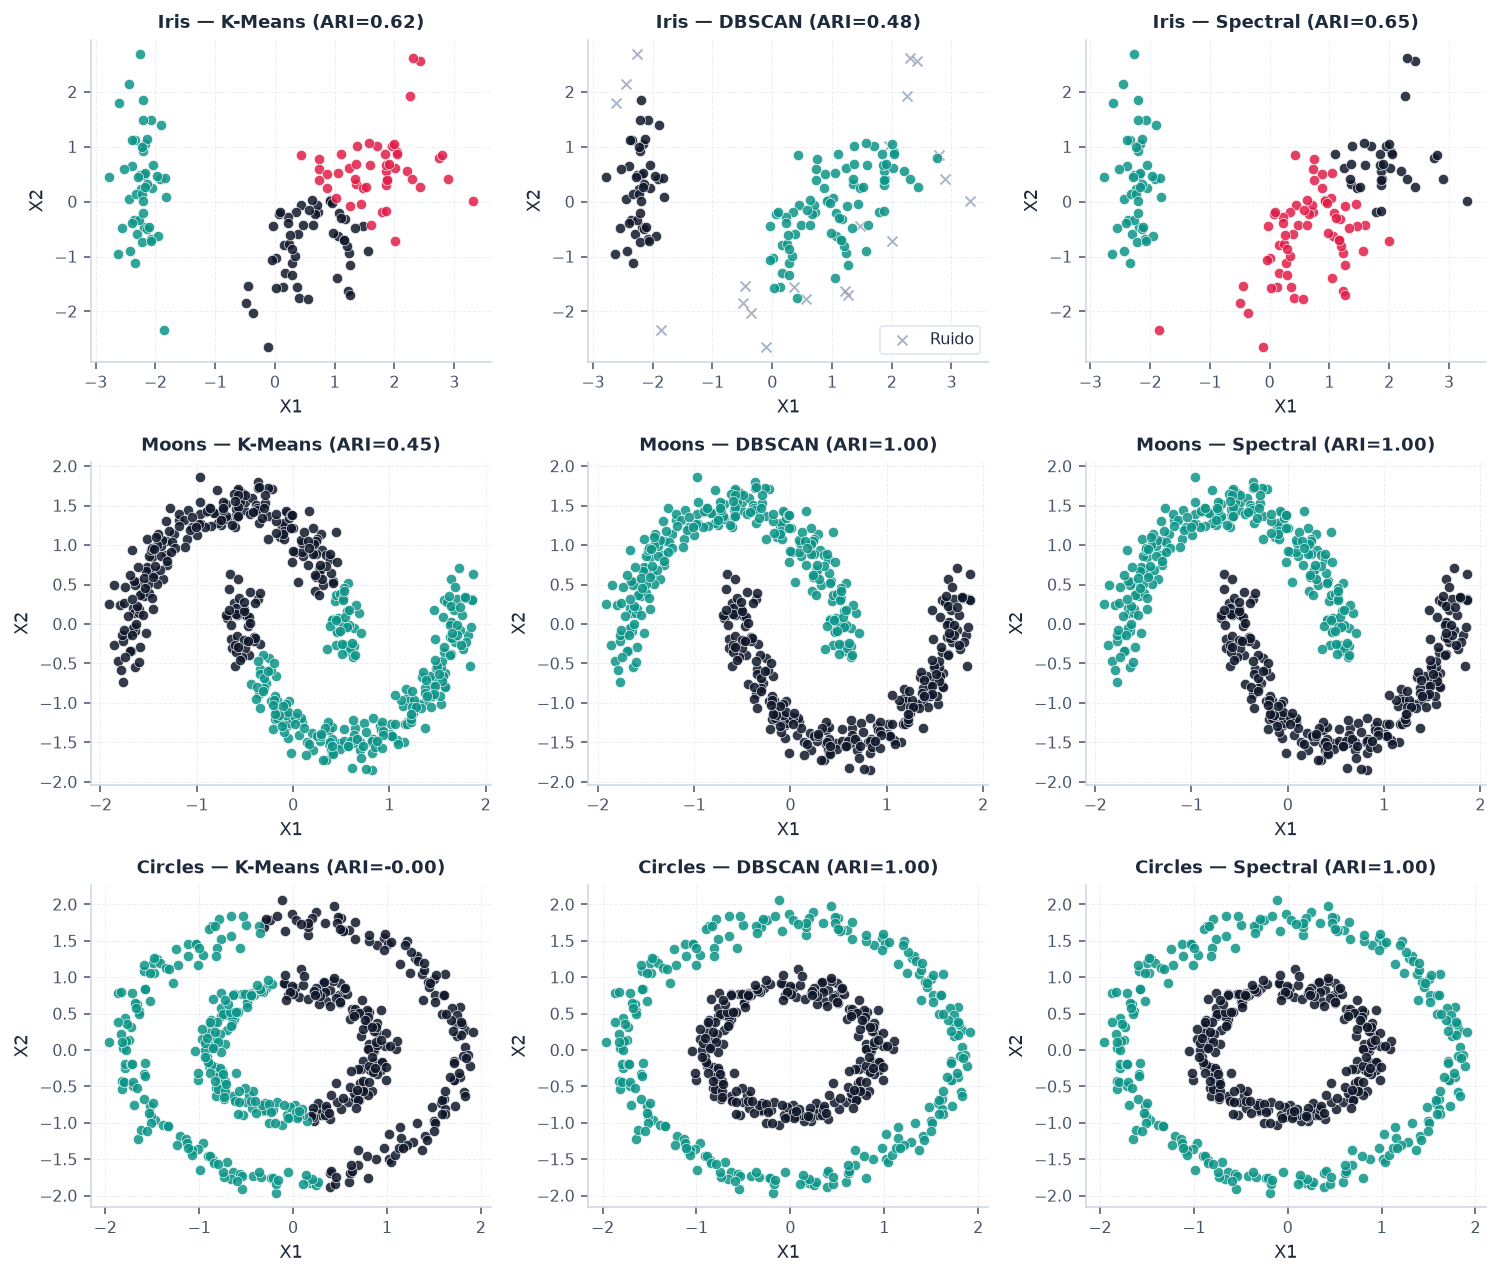

In [2]:
# Matriz 3x3 generada y trazada en vivo
fig, axes = plt.subplots(3, 3, figsize=(10.8, 9.2))
matrix_cases = [
    ("Iris", X_iris_2d, [("K-Means", y_km_iris, df_resumen.loc[0, "ARI"]), 
                         ("DBSCAN", y_db_iris, df_resumen.loc[1, "ARI"]), 
                         ("Spectral", y_sc_iris, df_resumen.loc[2, "ARI"])]),
    ("Moons", X_moons, [("K-Means", y_km_moons, df_resumen.loc[3, "ARI"]), 
                        ("DBSCAN", y_db_moons, df_resumen.loc[4, "ARI"]), 
                        ("Spectral", y_sc_moons, df_resumen.loc[5, "ARI"])]),
    ("Circles", X_circles, [("K-Means", y_km_circles, df_resumen.loc[6, "ARI"]), 
                           ("DBSCAN", y_db_circles, df_resumen.loc[7, "ARI"]), 
                           ("Spectral", y_sc_circles, df_resumen.loc[8, "ARI"])]),
]

for r_i, (d_name, X_plot, row_models) in enumerate(matrix_cases):
    for c_i, (m_title, y_p, ari_val) in enumerate(row_models):
        plot_scatter_minimal(axes[r_i, c_i], X_plot, y_p, 
                             f"{d_name} — {m_title} (ARI={ari_val:.2f})", 
                             xlabel="X1", ylabel="X2")

fig.tight_layout()
plt.show()

## 3. Calibración y sensibilidad de hiperparámetros (`eps` y `gamma`)

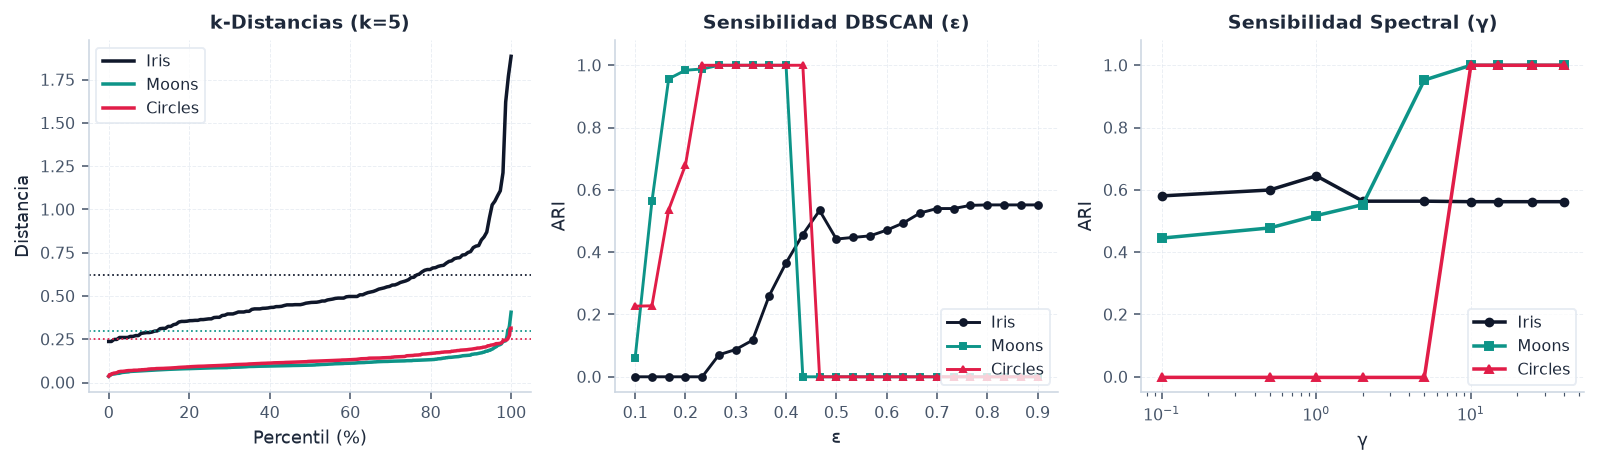

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))

# 1. k-distancias ordenadas (método de la rodilla)
for X_d, lbl_d, col_d, eps_opt in [
    (X_iris, "Iris", "#0F172A", 0.62),
    (X_moons, "Moons", "#0D9488", 0.30),
    (X_circles, "Circles", "#E11D48", 0.25),
]:
    dists, _ = NearestNeighbors(n_neighbors=5).fit(X_d).kneighbors(X_d)
    k_dists = np.sort(dists[:, -1])
    axes[0].plot(np.linspace(0, 100, len(k_dists)), k_dists, label=lbl_d, color=col_d, lw=1.8)
    axes[0].axhline(eps_opt, color=col_d, ls=":", lw=0.9)
axes[0].set_title("k-Distancias (k=5)")
axes[0].set_xlabel("Percentil (%)")
axes[0].set_ylabel("Distancia")
axes[0].legend(loc="upper left")

# 2. Barrido de eps en DBSCAN
eps_grid = np.linspace(0.10, 0.90, 25)
for X_d, y_d, lbl_d, col_d, m_k in [
    (X_iris, y_iris, "Iris", "#0F172A", "o"),
    (X_moons, y_moons, "Moons", "#0D9488", "s"),
    (X_circles, y_circles, "Circles", "#E11D48", "^"),
]:
    ari_vals = [adjusted_rand_score(y_d, DBSCAN(eps=e, min_samples=5).fit_predict(X_d)) for e in eps_grid]
    axes[1].plot(eps_grid, ari_vals, marker=m_k, ms=3.5, label=lbl_d, color=col_d, lw=1.5)
axes[1].set_title("Sensibilidad DBSCAN (ε)")
axes[1].set_xlabel("ε")
axes[1].set_ylabel("ARI")
axes[1].set_ylim(-0.05, 1.08)
axes[1].legend(loc="lower right")

# 3. Barrido de gamma en Spectral Clustering (RBF)
gamma_grid = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 15.0, 25.0, 40.0]
for X_d, y_d, k_c, lbl_d, col_d, m_k in [
    (X_iris, y_iris, 3, "Iris", "#0F172A", "o"),
    (X_moons, y_moons, 2, "Moons", "#0D9488", "s"),
    (X_circles, y_circles, 2, "Circles", "#E11D48", "^"),
]:
    ari_g = [adjusted_rand_score(y_d, SpectralClustering(n_clusters=k_c, affinity="rbf", gamma=g, random_state=42).fit_predict(X_d)) for g in gamma_grid]
    axes[2].semilogx(gamma_grid, ari_g, marker=m_k, ms=4, lw=1.8, label=lbl_d, color=col_d)
axes[2].set_title("Sensibilidad Spectral (γ)")
axes[2].set_xlabel("γ")
axes[2].set_ylabel("ARI")
axes[2].set_ylim(-0.05, 1.08)
axes[2].legend(loc="lower right")

fig.tight_layout()
plt.show()